# How-to 5 · Simulated data and the instrument registry

`sparta.instruments.Simulation` makes synthetic spectra "as if" from a real product, with a
known truth, through the same path as real files. `sparta.instruments.get` says what SPARTA
knows about each product (also listed in `docs/instruments.md`; a frame of `None` means the
archive does not document it).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sparta import Observations, instruments
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates
from sparta.plotting import apply_style, plot_data, plot_model

apply_style()        # SPARTA figure style: data black, model red, extra blue, maps grey

## The registry

In [2]:
print("survey keys:", ", ".join(sorted(instruments.REGISTRY)))
for key in ("HARPS", "NRES"):
    p = instruments.get(key)
    print(f"{key}: R = {p.instrument.resolving_power:,.0f}, native step {p.instrument.native_step_kms:.3f} km/s, "
          f"frame {p.wavelength_frame}, {p.specsys}, time {p.time_system}, "
          f"resampled by the archive: {p.resampled}, recommended window {p.recommended.window_A}")

survey keys: APOGEE, CORALIE, ELODIE, FEROS, FEROS-CERES, HARPS, HARPS-CERES, LAMOST, NRES, NRES-BANZAI, PEPSI, SIMULATED, SRG, TRES, UVES
HARPS: R = 120,000, native step 0.609 km/s, frame air, BARYCENT, time BJD (HARPS DRS; scale unverified), resampled by the archive: True, recommended window (4990.0, 5090.0)
NRES: R = 53,000, native step 1.450 km/s, frame None, TOPOCENT, time BJD-TDB, resampled by the archive: False, recommended window None


## An SB1 like HARPS

`components` are PHOENIX stars (bundled models, no download); `rv_kms` is one RV per epoch
(km/s); `snr` per native pixel; `noise='photon'` (σ ∝ √flux) or `'constant'`; `seed` makes the
noise reproducible. With `windows_A=None` the product's recommended window is used.

In [3]:
times = np.linspace(0, 10, 8)                                       # days
rv = 5.0 + 20.0 * np.sin(2 * np.pi * times / 3.7)                   # km/s
star = [dict(teff=5800, logg=3.5, feh=0.5, vsini=3.0)]

def simulate(**kw):
    return Simulation(like="HARPS", components=star, times=times, rv_kms=rv, **kw)

sim = simulate(snr=50, noise="photon", seed=1)
obs = Observations(survey="SIMULATED", simulation=sim)
again = Observations(survey="SIMULATED", simulation=simulate(snr=50, noise="photon", seed=1))
clean = Observations(survey="SIMULATED", simulation=simulate(snr=None))          # noiseless
archive = Observations(survey="SIMULATED", simulation=simulate(snr=50, seed=1, as_product=True))

sp = obs.spec_list[0]
print(f"{obs.sample_size} epochs, {len(sp.wv)} order {sp.wv[0][0]:.1f}-{sp.wv[0][-1]:.1f} Å, "
      f"frame {obs.wavelength_frame}")
print("same seed, same noise:", np.array_equal(sp.sp[0], again.spec_list[0].sp[0]))
print(f"pixel: native {np.median(np.diff(sp.wv[0])):.4f} Å, as_product {np.median(np.diff(archive.spec_list[0].wv[0])):.4f} Å")
tr = obs.truth
print(f"truth: like={tr.like}, rv_kms {tr.rv_kms.shape}, snr {tr.snr[0]}, noise {tr.noise}, "
      f"seed {tr.seed}, frame {tr.wavelength_frame}, convention {tr.velocity_convention}")

8 epochs, 1 order 4990.0-5090.0 Å, frame air
same seed, same noise: True
pixel: native 0.0102 Å, as_product 0.0100 Å
truth: like=HARPS, rv_kms (8, 1), snr 50.0, noise photon, seed 1, frame air, convention cz


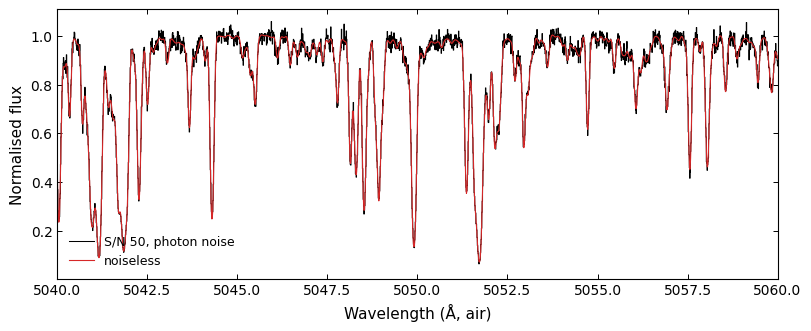

In [4]:
fig, ax = plt.subplots()
plot_data(ax, sp.wv[0], sp.sp[0], label="S/N 50, photon noise")
plot_model(ax, clean.spec_list[0].wv[0], clean.spec_list[0].sp[0], lw=0.8, label="noiseless")
ax.set_xlim(5040, 5060)
ax.set_xlabel("Wavelength (Å, air)")
ax.set_ylabel("Normalised flux")
ax.legend(loc="lower left")
plt.show()

The truth makes injection-recovery a few lines: the matched template is
`component_templates(sim)`.

In [5]:
obs.calc_rv_against_template(component_templates(sim)[0], dv=0.1, vel_bound=50)
resid = obs.vels - obs.truth.rv_kms[:, 0]
print(f"RV - truth: rms {resid.std() * 1e3:.1f} m/s, median eRV {np.median(obs.evels) * 1e3:.1f} m/s")

RV - truth: rms 4.2 m/s, median eRV 3.5 m/s


## An SB1 like NRES

NRES recommends no window, so give one per order. Its spectra are topocentric: `bcv_kms` is
removed on ingest exactly as for real files (`obs.bcv`), and the frame is vacuum.

In [6]:
bcv = np.linspace(-14, -12, times.size)                             # km/s
sim_nres = Simulation(like="NRES", components=star, times=times, rv_kms=rv, bcv_kms=bcv,
                      windows_A=[(5000, 5060), (5500, 5560)], snr=30, seed=2)
nres = Observations(survey="SIMULATED", simulation=sim_nres)
print(f"{len(nres.spec_list[0].wv)} orders, frame {nres.wavelength_frame}, "
      f"bcv applied: {np.round(nres.bcv[:3], 2)} ... km/s")

nres.calc_rv_against_template(component_templates(sim_nres)[0], dv=0.3, vel_bound=50)
resid = nres.vels - nres.truth.rv_kms[:, 0]
print(f"RV - truth: rms {resid.std() * 1e3:.1f} m/s, median eRV {np.median(nres.evels) * 1e3:.1f} m/s")

2 orders, frame vacuum, bcv applied: [-14.   -13.71 -13.43] ... km/s


RV - truth: rms 10.1 m/s, median eRV 13.6 m/s
